# Part 2 - Independent Component Analysis (Variant 2)

In this notebook we apply ICA to the preprocessed language task run, and then compare the components with the GLM regressors from Part 1. The input files come from 01_Preprocessing_GLM.ipynb.

In [1]:
### Setup: imports, paths, data loading
import os
import os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nibabel as nib
from scipy.stats import skew

from nilearn import image, masking, plotting, signal
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import make_first_level_design_matrix
from sklearn.decomposition import PCA, FastICA

code_dir = os.path.abspath("")
repository_dir = op.abspath(op.join(code_dir, '..'))
preproc_root = op.join(repository_dir, 'derivatives', 'preprocessed_data')
fMRI_path = op.join(repository_dir, 'fMRI', 'tfMRI_LANGUAGE_LR')
image_root = op.join(repository_dir, 'Images')
os.makedirs(image_root, exist_ok=True)

smoothed_fmri_path = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco_smoothed-4mm.nii.gz')
motion_par_path = op.join(preproc_root, 'func', 'tfMRI_LANGUAGE_LR_moco.par')
anat_mask_path = op.join(preproc_root, 'anat', 'T1_biascorr_brain_mask.nii.gz')
anat_brain_path = op.join(preproc_root, 'anat', 'T1_biascorr_brain.nii.gz')
events_csv_path = op.join(fMRI_path, 'tfMRI_LANGUAGE_LR_task_onsets.csv')
assert op.exists(smoothed_fmri_path), f"Run 01_Preprocessing_GLM.ipynb first: {smoothed_fmri_path} not found"

fmri_img = nib.load(smoothed_fmri_path)
tr = float(fmri_img.header.get_zooms()[3])
n_scans = fmri_img.shape[3]
mean_img = image.mean_img(fmri_img)

# anatomical brain mask resampled to the fMRI grid
mask_img = image.resample_to_img(anat_mask_path, mean_img, interpolation='nearest')
print(f"TR = {tr:.2f} s, {n_scans} volumes, {int(mask_img.get_fdata().sum())} brain voxels")

TR = 0.72 s, 316 volumes, 163930 brain voxels


## Part 1 - Apply ICA


Each timepoint is a sample and each brain voxel is a feature, so the data matrix has the shape timepoints x voxels. Before ICA, every voxel timecourse is detrended, high-pass filtered at 0.01 Hz (as in the GLM) and normalized. FastICA then gives one timecourse and one spatial map per component. We fixed the random seed so that the order of the components is always the same, and we flipped the sign of each component so that its strongest values are positive, since the sign of an ICA component is arbitrary.

In [2]:
masker = NiftiMasker(mask_img=mask_img, standardize='zscore_sample', detrend=True,
                     high_pass=0.01, t_r=tr)
X = masker.fit_transform(fmri_img).astype(np.float32)
print("X shape (n_timepoints, n_voxels):", X.shape)

N_COMPONENTS = 20   # justified in Part 2

ica = FastICA(n_components=N_COMPONENTS, whiten='unit-variance', random_state=42,
              max_iter=2000, tol=1e-4)
timecourses = ica.fit_transform(X)      # (n_timepoints, k): one timecourse per component
spatial = ica.mixing_.copy()            # (n_voxels, k): one spatial map per component
print("FastICA converged in", ica.n_iter_, "iterations")
print("Timecourses:", timecourses.shape, "| spatial maps:", spatial.shape)

# Sign convention: positive skew of each spatial map
signs = np.sign(skew(spatial, axis=0))
signs[signs == 0] = 1
spatial *= signs
timecourses = timecourses * signs

X shape (n_timepoints, n_voxels): (316, 163930)


FastICA converged in 272 iterations
Timecourses: (316, 20) | spatial maps: (163930, 20)


## Part 2 - Number of components and spatial maps


ICA needs the number of components in advance. As in the lab, we look at the variance explained by PCA on the same data and use the elbow criterion. Since the elbow is not always clear, we also added a baseline: we shuffle each voxel's timecourse in time, which removes any real structure, and run the PCA again. Components that explain more variance than this shuffled data contain real signal and not only noise.

Variance explained by the first 20 components: 30.1%
Components above the shuffled-data null: 39


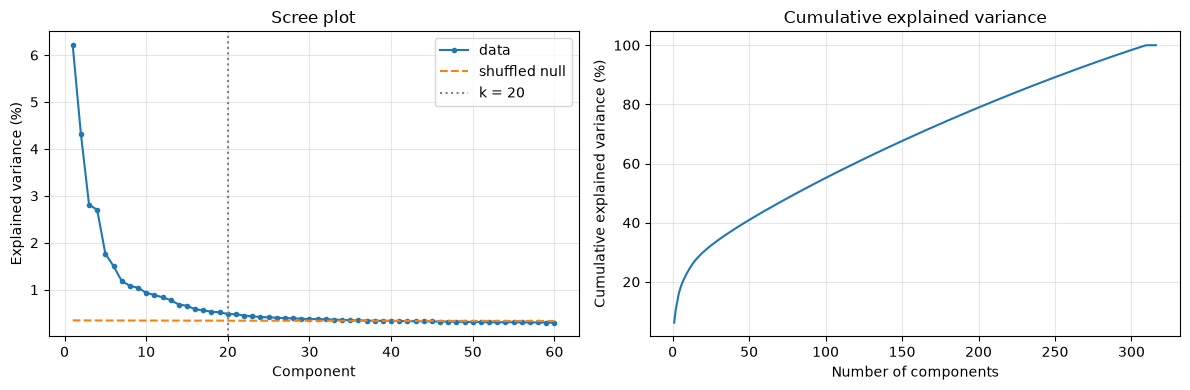

In [3]:
pca = PCA(svd_solver='full').fit(X)
var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

# Parallel analysis: shuffle each voxel's timecourse independently
rng = np.random.default_rng(0)
X_null = rng.permuted(X, axis=0)
null_var_ratio = PCA(svd_solver='full').fit(X_null).explained_variance_ratio_
del X_null

n_above_null = int(np.argmax(var_ratio < null_var_ratio))
print(f"Variance explained by the first {N_COMPONENTS} components: {cum_var[N_COMPONENTS - 1] * 100:.1f}%")
print(f"Components above the shuffled-data null: {n_above_null}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
n_show = 60
axes[0].plot(np.arange(1, n_show + 1), var_ratio[:n_show] * 100, 'o-', ms=3, label='data')
axes[0].plot(np.arange(1, n_show + 1), null_var_ratio[:n_show] * 100, '--', label='shuffled null')
axes[0].axvline(N_COMPONENTS, color='gray', ls=':', label=f'k = {N_COMPONENTS}')
axes[0].set_xlabel('Component'); axes[0].set_ylabel('Explained variance (%)')
axes[0].set_title('Scree plot'); axes[0].legend()
axes[1].plot(np.arange(1, len(cum_var) + 1), cum_var * 100)
axes[1].set_xlabel('Number of components'); axes[1].set_ylabel('Cumulative explained variance (%)')
axes[1].set_title('Cumulative explained variance')
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(op.join(image_root, 'ICA_n_components_selection.png'), dpi=300)
plt.show()

Justification:

The scree plot drops quickly over the first 5 to 7 components, then decreases slowly and flattens around 15 to 20 components. There is no single clear elbow, so the curve alone does not give an exact number. The shuffled baseline helps here: the data stays above the noise level only up to 39 components, so 39 is an upper limit.

We chose 20 components, which is at the end of the elbow region and well below this limit (they explain about 30% of the variance). With fewer components, around 10, different networks such as the language and auditory areas could be merged into one map. With more components, close to 39, we would mostly add noise and ICA would split the networks into small pieces. 


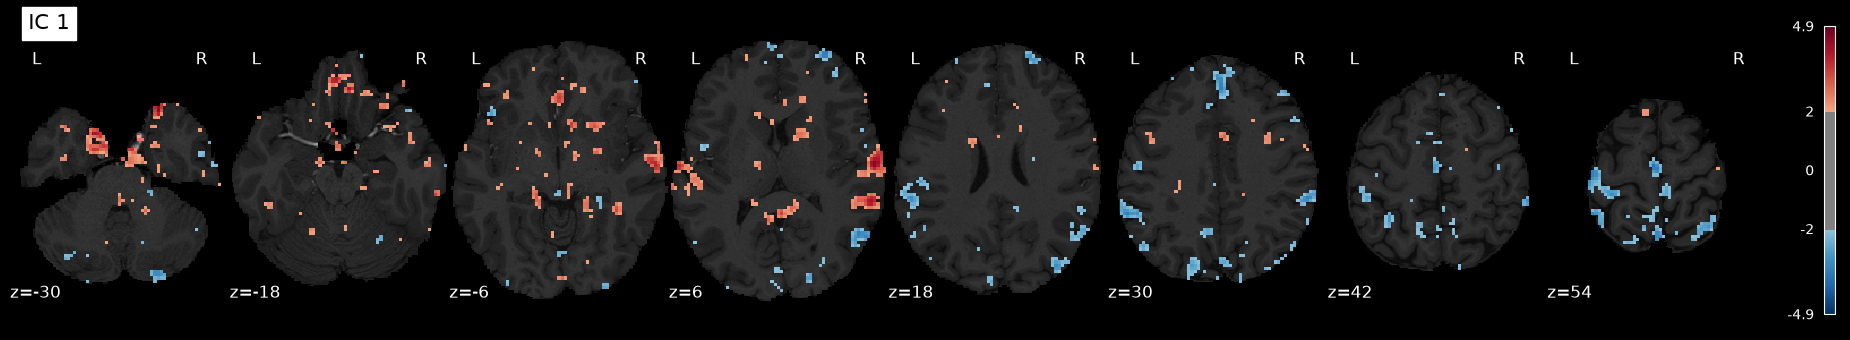

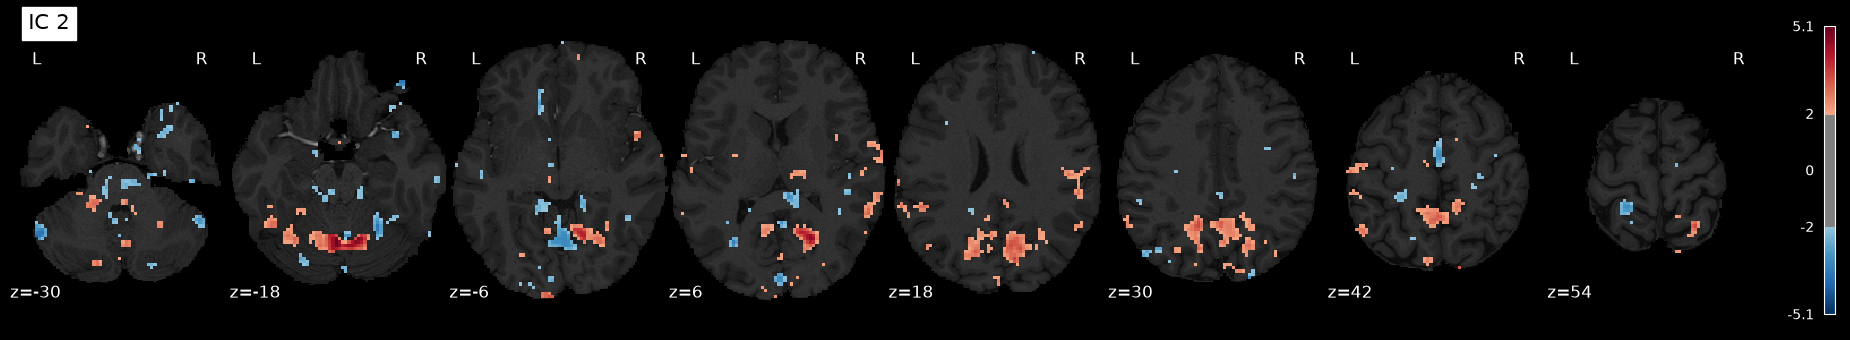

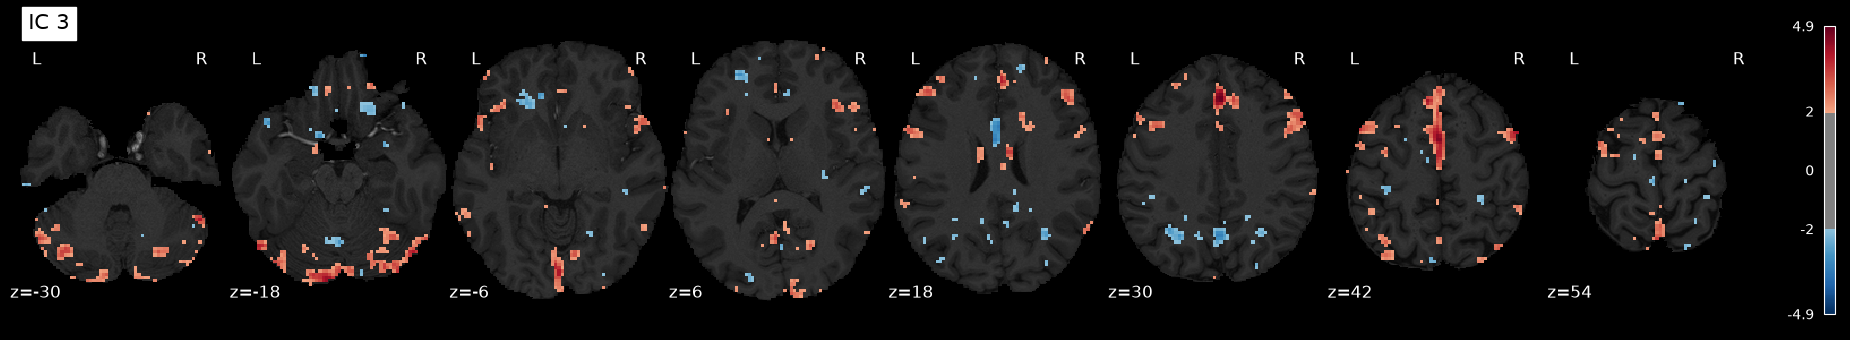

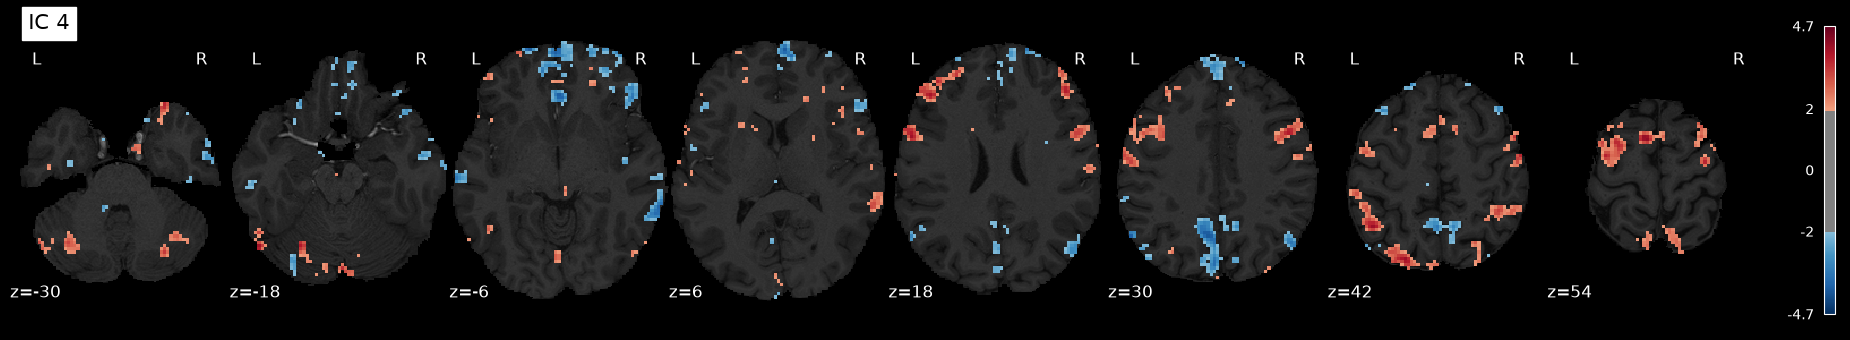

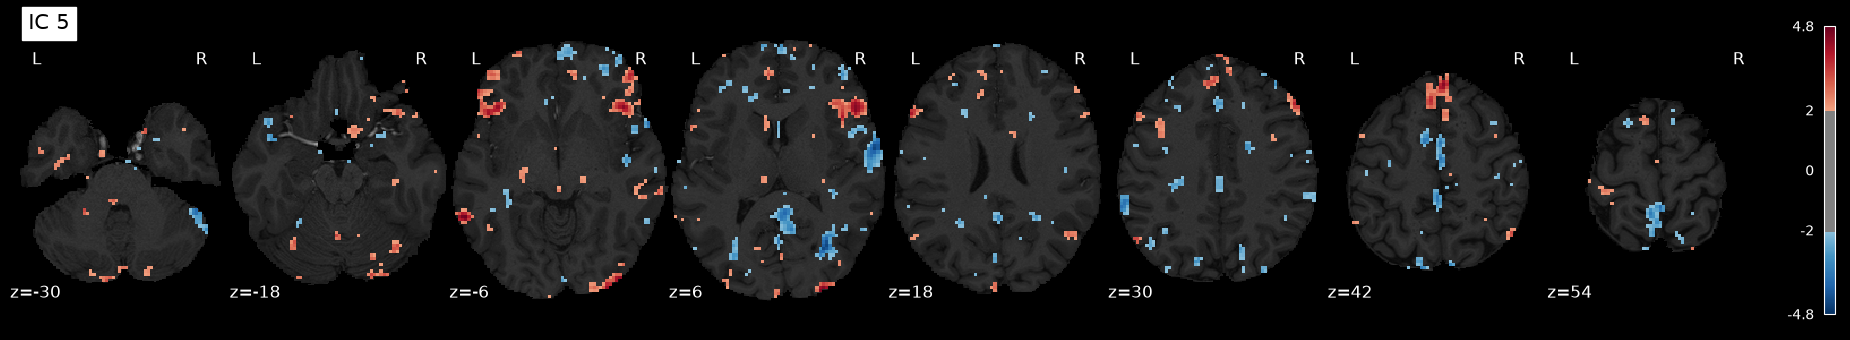

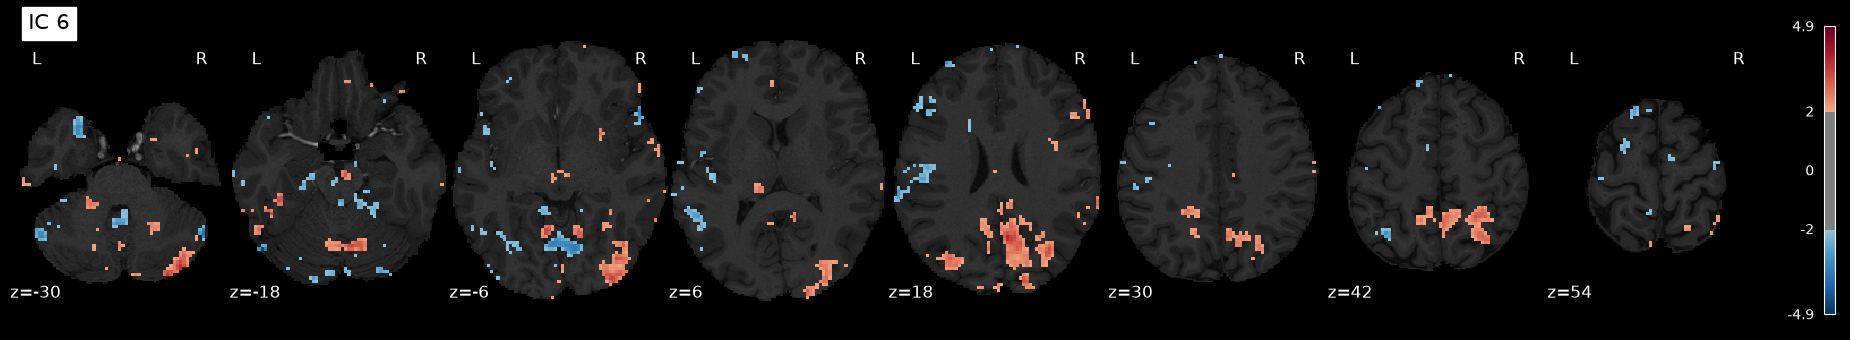

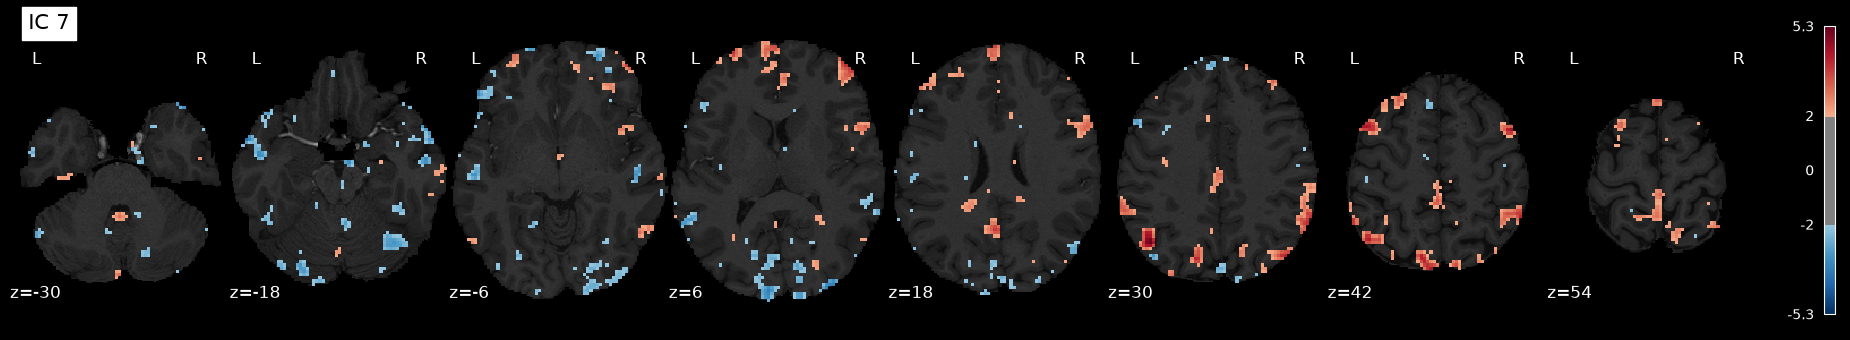

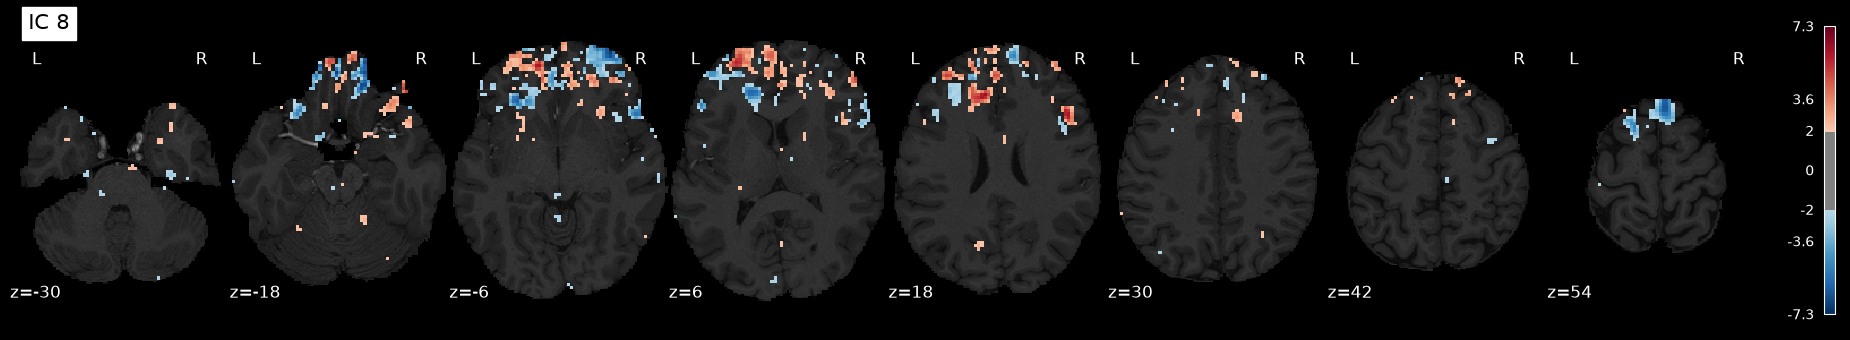

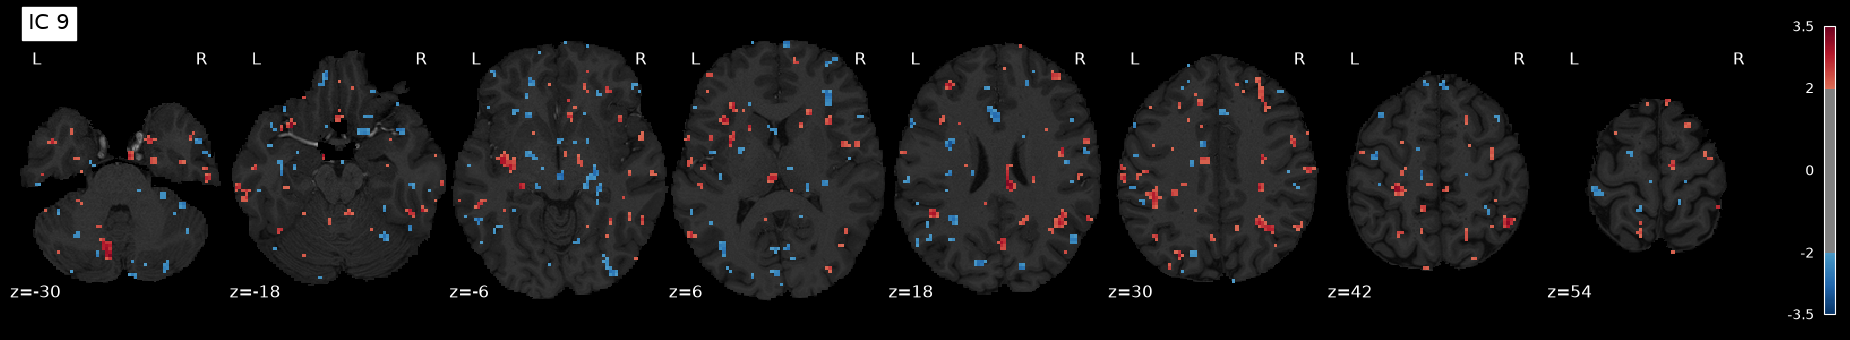

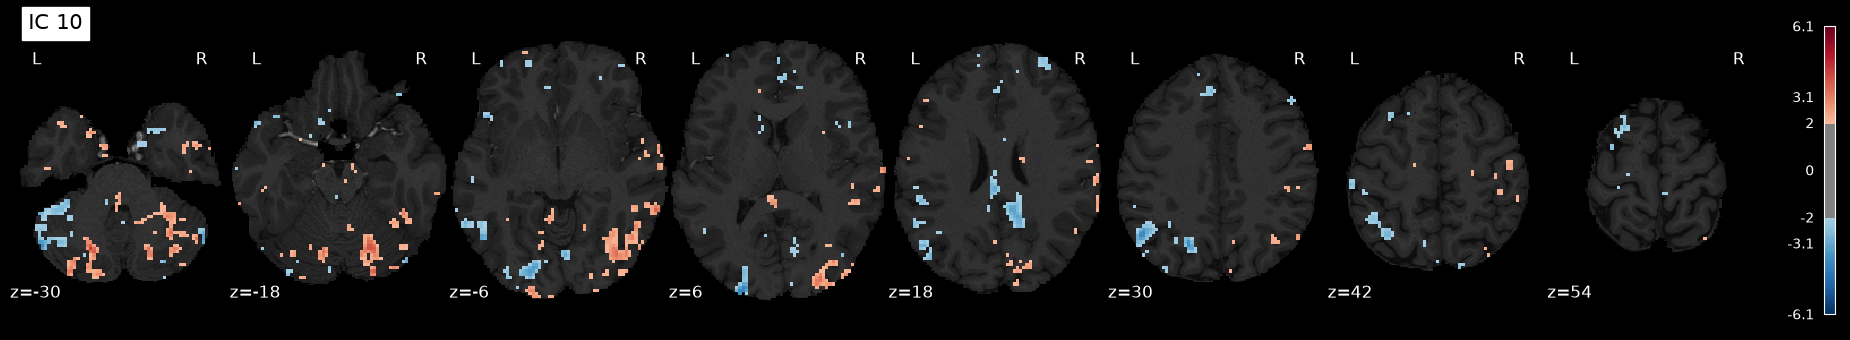

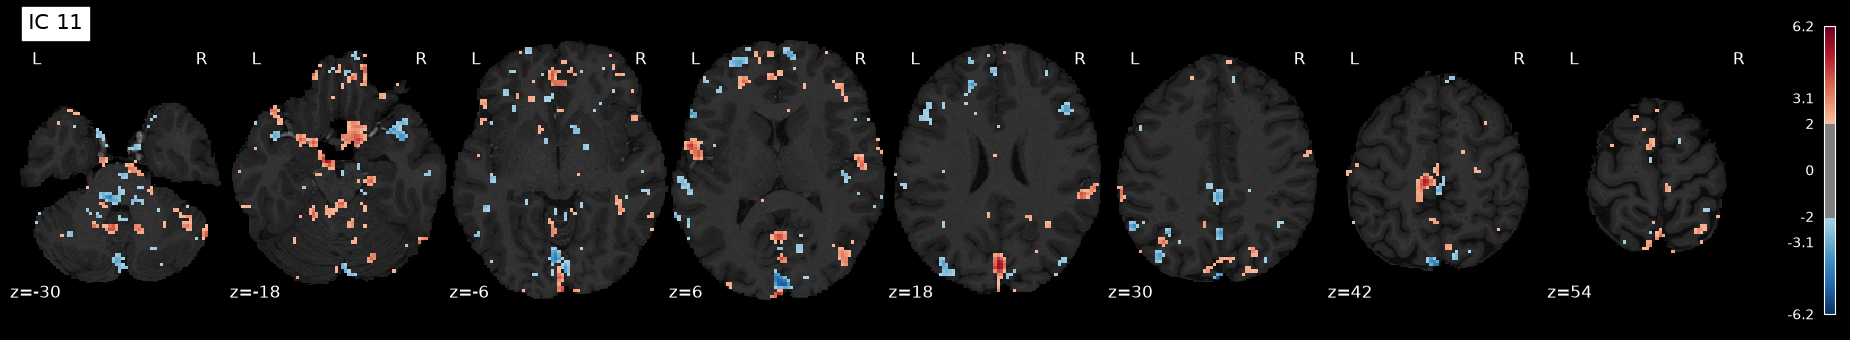

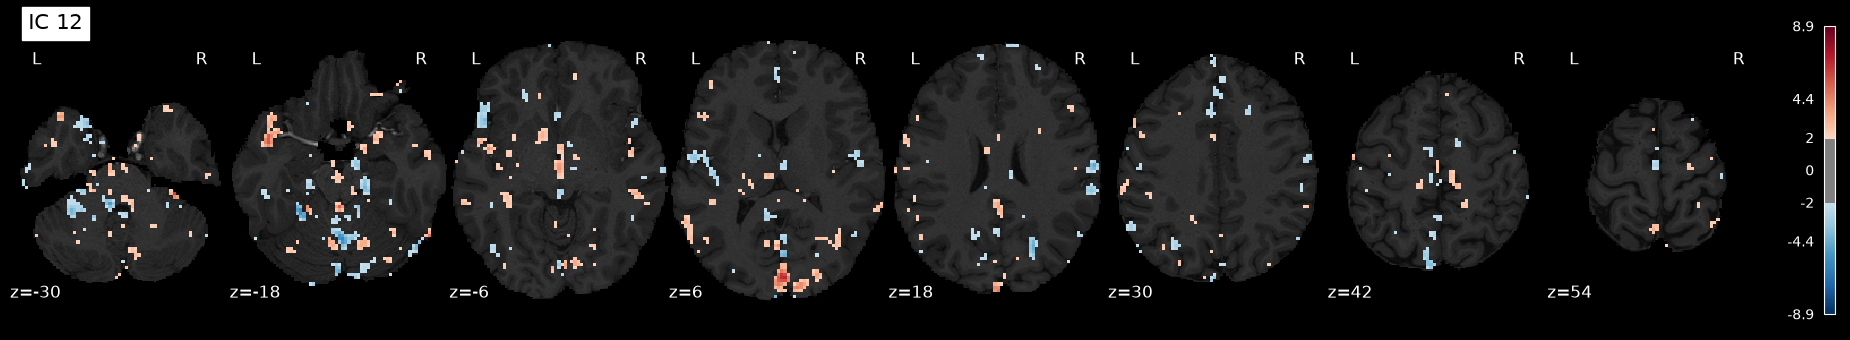

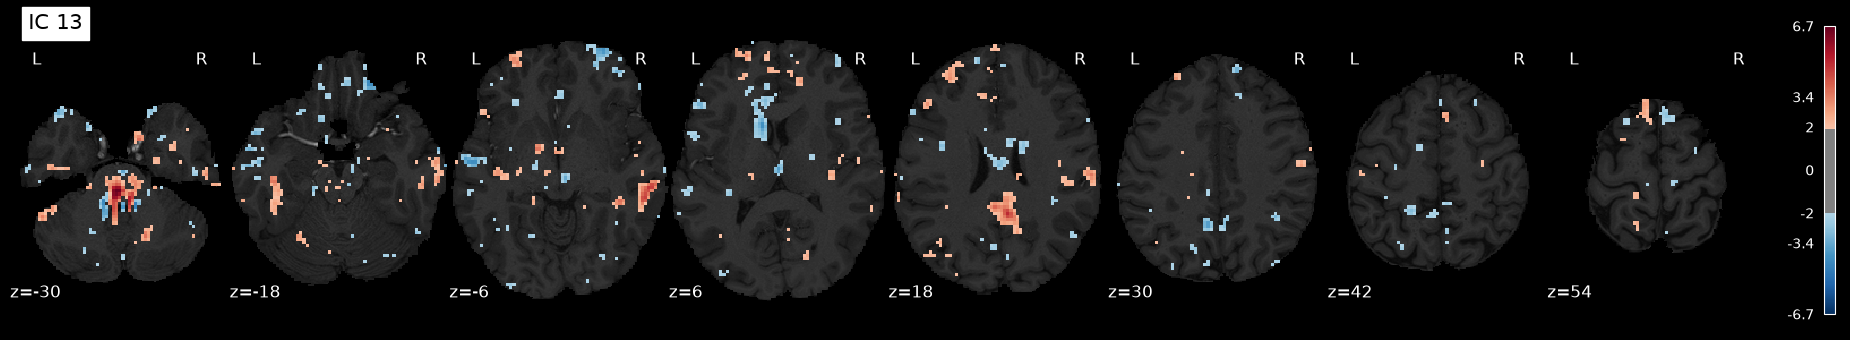

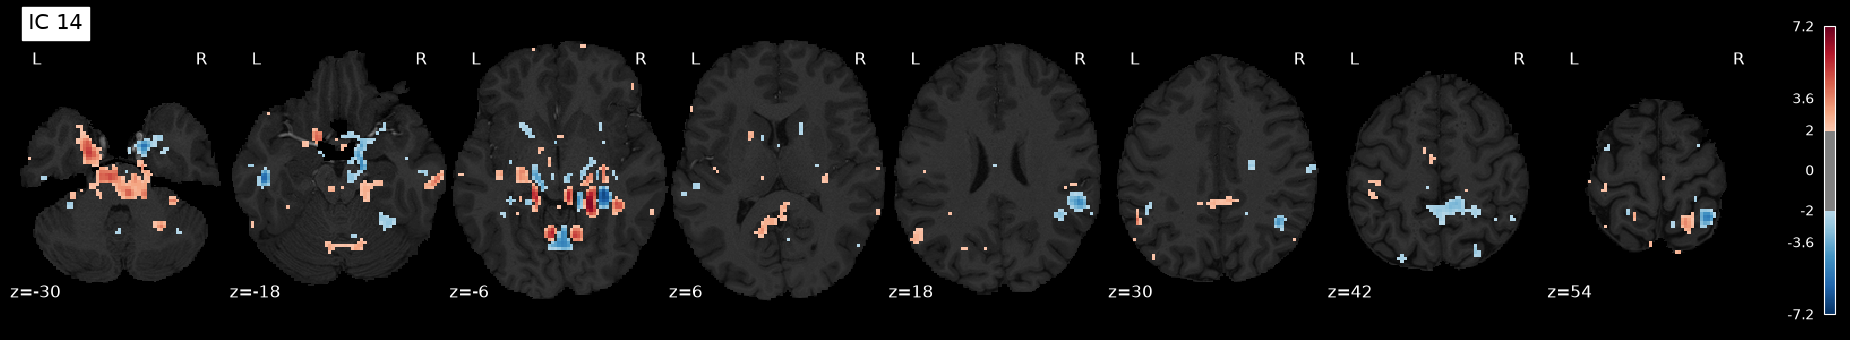

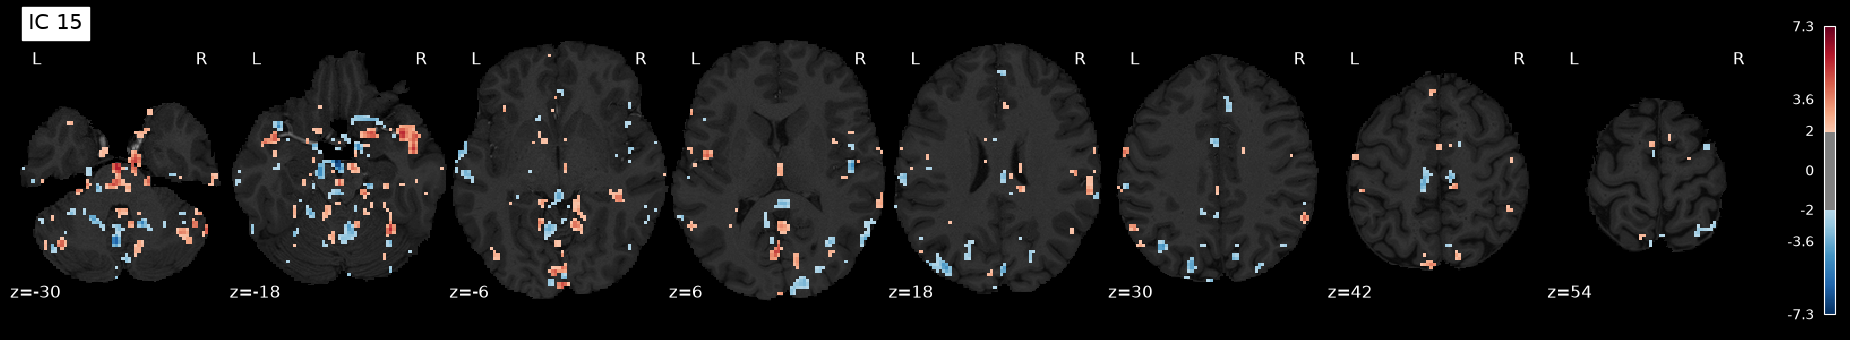

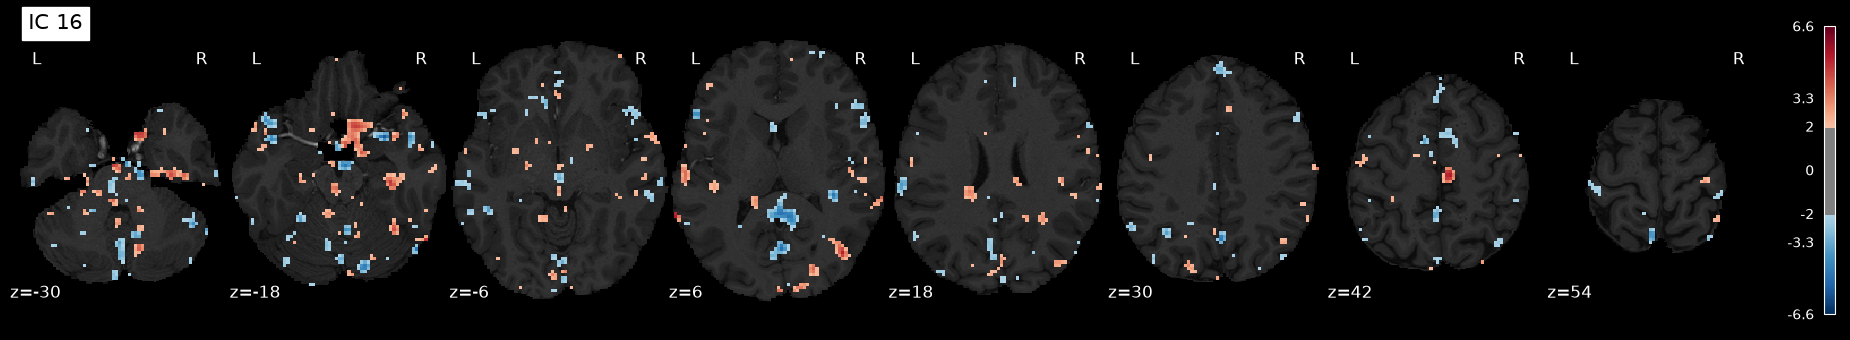

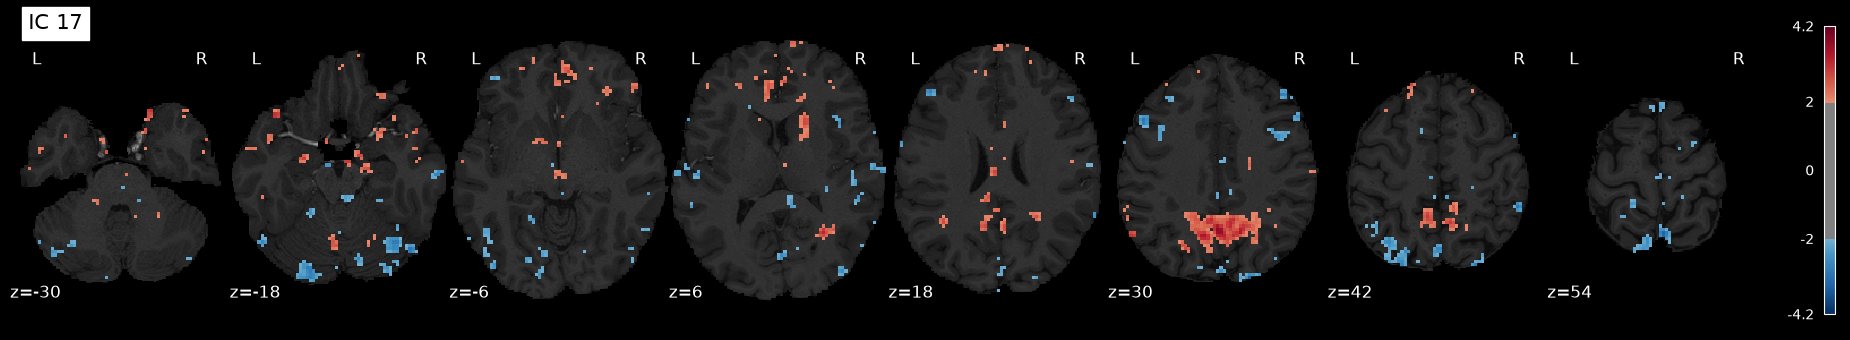

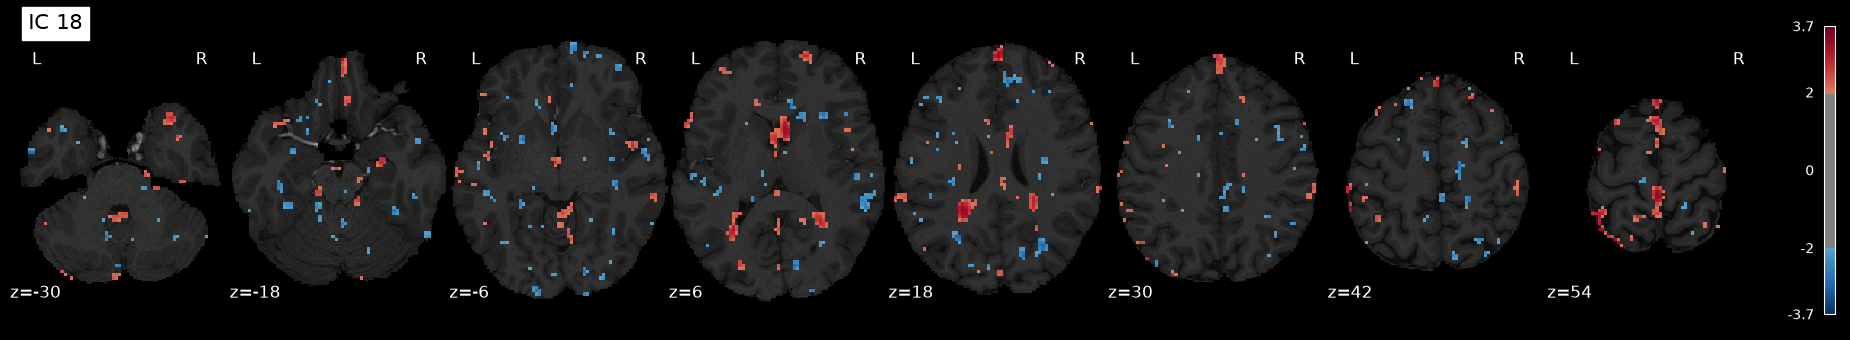

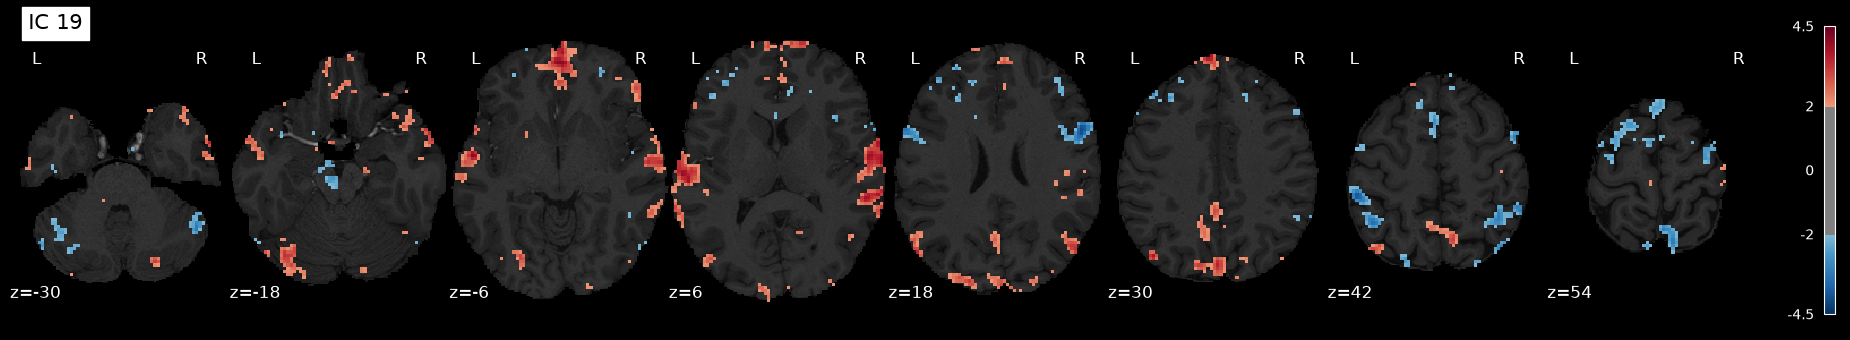

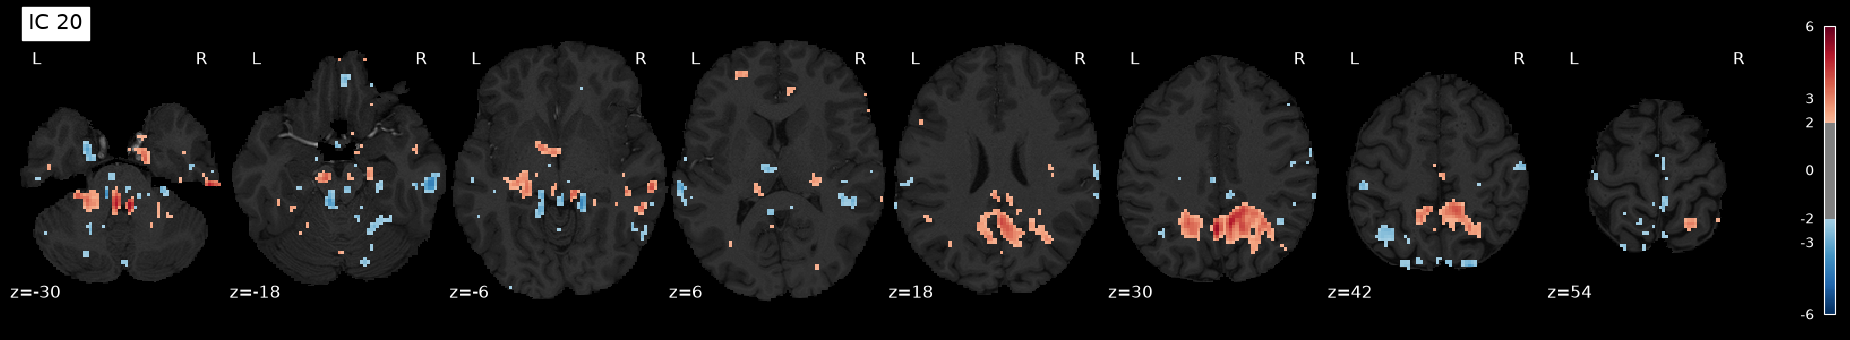

In [ ]:
Z_THR = 2   #threshold at 2 x std of each map
CUT_COORDS = [-30, -18, -6, 6, 18, 30, 42, 54]

maps_z = (spatial - spatial.mean(axis=0)) / spatial.std(axis=0)   # z-score each map across voxels
maps_img = masker.inverse_transform(maps_z.T)

for i in range(N_COMPONENTS):
    display = plotting.plot_stat_map(
        image.index_img(maps_img, i), bg_img=anat_brain_path, display_mode='z', cut_coords=CUT_COORDS,
        threshold=Z_THR, black_bg=True, title=f'IC {i + 1}', colorbar=True)
    display.savefig(op.join(image_root, f'ICA_IC{i + 1:02d}_axial.png'), dpi=200)
    plt.show()

Results:

Some maps look like known brain networks, for example IC 4 (frontal and parietal regions) and IC 19 (lateral temporal cortex on both sides, where the auditory and language areas are). Others look like noise, such as IC 8 at the edge of the brain or IC 12 to 16, which are mostly scattered voxels in the brainstem and cerebellum.

## Part 3 - Correlation with the GLM regressors

The regressors are built in the same way as in the Part 1 GLM. We kept the three block regressors (story, math and cue), the sub-event regressors (presentation, question and response of each task) and the six motion parameters. The sub-events were not used in the GLM because they overlap with the blocks, but this is not a problem for correlations, and they help to see which part of the task a component follows. The regressors are filtered in the same way as the data so that the comparison is fair.

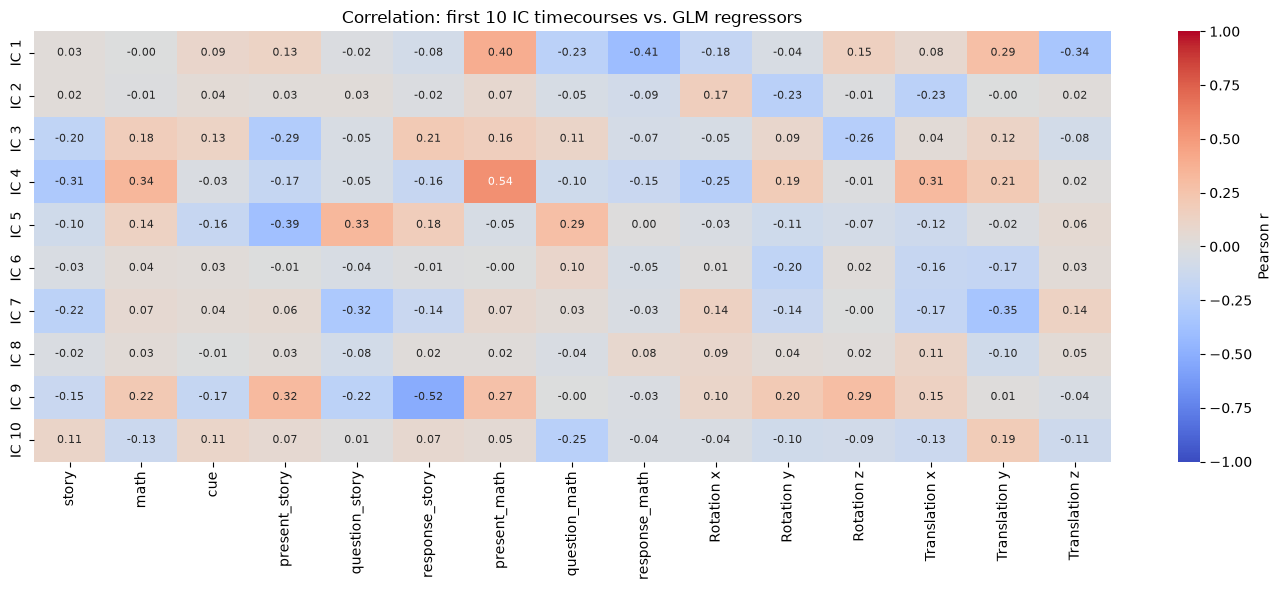

,best regressor,r
IC 1,response_math,-0.41
IC 2,Rotation y,-0.23
IC 3,present_story,-0.29
IC 4,present_math,0.54
IC 5,present_story,-0.39
IC 6,Rotation y,-0.20
IC 7,Translation y,-0.35
IC 8,Translation x,0.11
IC 9,response_story,-0.52
IC 10,question_math,-0.25


In [5]:
events_df = pd.read_csv(events_csv_path)
frame_times = np.arange(n_scans) * tr
mot_params = pd.read_csv(motion_par_path, sep=r'\s+', header=None,
                         names=['Rotation x', 'Rotation y', 'Rotation z',
                                'Translation x', 'Translation y', 'Translation z'])

dm = make_first_level_design_matrix(
    frame_times=frame_times, events=events_df[['onset', 'duration', 'trial_type']],
    hrf_model='glover', drift_model=None,
    add_regs=mot_params.values, add_reg_names=mot_params.columns.tolist())

task_blocks = ['story', 'math', 'cue']
sub_events = ['present_story', 'question_story', 'response_story',
              'present_math', 'question_math', 'response_math']
regressor_names = task_blocks + sub_events + mot_params.columns.tolist()

# Same temporal filtering as the data matrix X (NiftiMasker uses this same function)
regressors = pd.DataFrame(
    signal.clean(dm[regressor_names].values, detrend=True, high_pass=0.01, t_r=tr, standardize=None),
    index=dm.index, columns=regressor_names)

# Correlation between the first 10 IC timecourses (FastICA order) and the regressors
n_first = 10
ic_names = [f'IC {i + 1}' for i in range(n_first)]
full_corr = np.corrcoef(np.column_stack([timecourses[:, :n_first], regressors.values]), rowvar=False)
corr = pd.DataFrame(full_corr[:n_first, n_first:], index=ic_names, columns=regressor_names)

plt.figure(figsize=(14, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 8},
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlation: first 10 IC timecourses vs. GLM regressors')
plt.tight_layout()
plt.savefig(op.join(image_root, 'ICA_correlation_matrix.png'), dpi=300)
plt.show()

summary = pd.DataFrame({'best regressor': corr.abs().idxmax(axis=1),
                        'r': [corr.loc[ic, corr.abs().loc[ic].idxmax()] for ic in ic_names]})
summary.round(2)

Results:

Overall the correlations are moderate (at most 0.54), so none of the first 10 components matches a task regressor perfectly. This is expected, since ICA does not know anything about the task and each component also contains noise and spontaneous activity.

IC 4 is the clearest task-related component. Its timecourse correlates with the math presentation (r = 0.54) and the math blocks (r = 0.34), and negatively with the story blocks (r = -0.31). Its map shows the frontoparietal network, which fits the math > story regions we found with the GLM in Part 1. The posterior cingulate cortex, which has the opposite sign in the map, belongs to the default mode network, which usually decreases during demanding tasks like mental calculation.

IC 1 correlates positively with the math presentation (r = 0.40) and negatively with the math response (r = -0.41), so it separates the moments when the subject listens to the math problem from the moments when they answer. Its map includes lateral temporal regions, which makes sense for auditory input.

IC 5 and IC 9 follow the structure of the story trials rather than the story blocks as a whole. IC 9 correlates negatively with the story response (r = -0.52) and positively with the story presentation (r = 0.32), while IC 5 shows the opposite pattern (r = -0.39 with the story presentation and r = 0.33 with the story question).

IC 7 correlates with the story question (r = -0.32) but also with a motion parameter (translation in y, r = -0.35), so it is probably a mix of task activity and head motion.

IC 2, 3, 6, 8 and 10 have weak correlations with the task (|r| < 0.3). IC 2 is mostly related to the motion parameters, IC 3 weakly to both the story events and head rotation, and IC 8, which lies at the edge of the brain, does not correlate with anything. These components are most likely noise or spontaneous activity, which fits what we see in their maps.

Finally, ICA does not sort the components in a meaningful order, unlike PCA where the first component always explains the most variance. This is why the component that looks most like the language network, IC 19, is not among the first 10, even though its map matches the story > math regions from Part 1 well.